> **中文阅读版**：本文件是 `14_text_data_extraction.ipynb` 的 Markdown 翻译副本。代码、输出、图表和路径保持原样；专有名词和标识符保留英文。
# 文本数据提取：非结构化金融文档的结构化

**第4章：基本面和替代数据
**Docker镜像：`ml4t`
**章节参考**：第4.5节（使用文本数据创建NLP特征）

## 目的

年度报告有25万个字符，而模型可能只需要其中的二十分之一。证券交易委员会规定了10-K必须包含的内容，并对各部分进行了编号，因此文档具有结构；它没有的是解析器可以依赖的标记，因为编号出现在目录中、在叙述中的交叉引用中，以及再次作为实际章节标题，无论文件提交者选择了什么字体。

从一份文件到章节的定位，在数千份文件中可靠地完成，这就是这个笔记本的全部工作。本书下游的所有内容——情感评分、主题模型、嵌入——都假设这项工作已经正确完成，失败模式是沉默的：一个返回目录条目而不是章节的提取器返回了一个看似合理的短字符串。

## 学习目标

完成这个笔记本后，你将能够：

- 列出10-K中研究管道通常想要的条目，并说明相同内容在10-Q中的位置。
- 从文件中剥离HTML，而不破坏后续阶段需要的段落边界。
- 当一个章节的项目编号在文档中多次出现时，定位该章节的边界，并解释为什么第一个匹配项是错误的。
- 检查提取可能出现的两种失败情况——返回空值和超出章节末尾——并报告比率而不是假设成功。
- 测量两个连续文件之间一个章节的变化量，这是第10章中变化检测信号输入。

## 先决条件

这个笔记本从EDGAR读取实时文件，需要识别`User-Agent`。这不是API密钥，也没有需要注册的内容：在启动Jupyter之前，在存储库根目录中的`.env`文件的`EDGAR_IDENTITY`行上填写你自己的姓名和电子邮件。


EDGAR_IDENTITY=Jane Doe jane@example.org


## 交叉引用

- **相关**：[`02_sec_filing_explorer`](02_sec_filing_explorer.ipynb)（通过库获取文件）
- **下游**：`10_text_feature_engineering/09_filing_text_signals.py`（基于文件文本构建的信号）

## 关键概念

- **10-K**：年度报告，每年提交一次，是最完整的叙述性披露。
- **10-Q**：季度报告，较短，内容相同，但项目编号不同。
- **项目1A，风险因素**：管理层必须披露的风险。
- **项目7，管理层讨论与分析**：管理层对本期结果的描述。
- **存取编号**：SEC分配给文件的标识符。唯一、永久，并且是文本数据集的正确主键。

In [1]:
"""Text Data Extraction - extract and structure high-value text blocks from SEC filings for NLP analysis."""

import os
import re
import warnings

# EdgarTools re-exports three legacy HTML helpers and each one raises a DeprecationWarning as it
# is imported. They are the same three every time and say nothing about the filings.
warnings.filterwarnings("ignore", category=DeprecationWarning, module="edgar")

import plotly.express as px
import polars as pl
from bs4 import BeautifulSoup
from edgar import Company, set_identity

from utils.paths import get_output_dir
from utils.style import COLORS, show_plotly_with_alt

公司和表格选择读取哪些文件。获取两个相同形式的连续文件，因为第二个文件使得第6部分的变化测量成为可能；单独的文件可以提取但不能比较。

In [2]:
TICKER = "AAPL"  # any filer with a long 10-K history works here
FORM = "10-K"  # switch to "10-Q" to exercise the quarterly item numbering
N_FILINGS = 2  # consecutive filings to read, most recent first
MIN_SECTION_WORDS = 100  # an extraction shorter than this is treated as a failure
MAX_SECTION_WORDS = 50_000  # and one longer than this as having run past its boundary

In [3]:
OUTPUT_DIR = get_output_dir(4, "sec_text")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. 文件由什么组成

10-K是一系列编号的项目，其含义由法规固定。其中三个包含了研究管道几乎所有的叙述。

| 项目 | 章节 | 包含内容 |
|------|---------|---------------|
| 1 | 业务 | 公司做什么，其部门及其市场 |
| 1A | 风险因素 | 管理层必须披露的风险 |
| 7 | 管理层讨论与分析 | 管理层对本期结果的描述 |
| 7A | 定量与定性披露 | 市场风险敞口 |
| 8 | 财务报表 | 审计后的财务报表 |

编号是**表格特定的**，这是无声提取为空的最常见原因。在10-Q中，管理层的讨论是第一部分的第2项，而不是第7项，风险因素，如果有所更新，是第二部分的第1A项。一个硬编码10-K编号的提取器在10-Q上返回空值，并且没有说明原因。

In [4]:
SECTIONS = {
    "10-K": {
        "business": {
            "starts": [r"^\s*ITEM\s*1\.?\s*[-–—]?\s*BUSINESS"],
            "ends": [r"^\s*ITEM\s*1A\b", r"^\s*ITEM\s*2\b"],
        },
        "risk_factors": {
            "starts": [r"^\s*ITEM\s*1A\.?\s*[-–—]?\s*RISK\s*FACTORS"],
            "ends": [r"^\s*ITEM\s*1B\b", r"^\s*ITEM\s*2\b"],
        },
        "mda": {
            # Filers use both the straight and the curly apostrophe in "Management's".
            "starts": [r"^\s*ITEM\s*7\.?\s*[-–—]?\s*MANAGEMENT(?:'|’)?S?\s*DISCUSSION"],
            "ends": [r"^\s*ITEM\s*7A\b", r"^\s*ITEM\s*8\b"],
        },
    },
    "10-Q": {
        "risk_factors": {
            "starts": [r"^\s*ITEM\s*1A\.?\s*[-–—]?\s*RISK\s*FACTORS"],
            "ends": [r"^\s*ITEM\s*1B\b", r"^\s*ITEM\s*2\b"],
            "after": r"PART\s*II",
        },
        "mda": {
            "starts": [r"^\s*ITEM\s*2\.?\s*[-–—]?\s*MANAGEMENT(?:'|’)?S?\s*DISCUSSION"],
            "ends": [r"^\s*ITEM\s*3\b"],
        },
    },
}
FLAGS = re.IGNORECASE | re.MULTILINE | re.DOTALL

## 2. 文件

EDGAR要求每个请求都标识其发送者，并拒绝占位符地址。获取操作是只读的，并且由库限制速率。

In [5]:
identity = os.environ.get("EDGAR_IDENTITY")
if not identity:
    raise RuntimeError(
        "EDGAR_IDENTITY is not set. The SEC requires a real User-Agent - your "
        "name and email - on every EDGAR request, and blocks placeholder "
        "addresses. It is not an API key and there is nothing to sign up for.\n"
        "Put your own name and email on the EDGAR_IDENTITY line of the .env "
        "file in the repository root:\n"
        "    EDGAR_IDENTITY=Jane Doe jane@example.org\n"
        ".env is read once, when the process starts, so then restart this "
        "notebook's kernel (Kernel -> Restart Kernel). On the Docker path, stop "
        "Jupyter Lab and run `docker compose up ml4t` again - `docker compose "
        "restart` keeps the environment the container was created with."
    )
set_identity(identity)

# `amendments=False` keeps 10-K/A out of the list. An amendment covers a period the original
# already covered and often omits the narrative items entirely, so a pair drawn without this
# filter can be two filings of the same period presented as consecutive ones.
filings = Company(TICKER).get_filings(form=FORM, amendments=False)[:N_FILINGS]
documents = [
    {
        "cik": filing.cik,
        "company_name": filing.company,
        "accession_no": filing.accession_no,
        "form": filing.form,
        "filing_date": filing.filing_date,
        "accepted_at": filing.acceptance_datetime,
        "period_end": filing.period_of_report,
        "text": filing.text(),
    }
    for filing in filings
]

pl.DataFrame(
    [
        {
            "accession_no": d["accession_no"],
            "filing_date": d["filing_date"],
            "period_end": d["period_end"],
            "characters": len(d["text"]),
        }
        for d in documents
    ]
)

accession_no,filing_date,period_end,characters
str,date,str,i64
"""0000320193-25-000079""",2025-10-31,"""2025-09-27""",260861
"""0000320193-24-000123""",2024-11-01,"""2024-09-28""",256286


接受时间戳值得与文件日期一起携带。一份在收盘后接受的文件当天晚上公开，第二天早上可交易，而仅根据文件日期采取行动的策略在每次盘后提交上都提前几个小时。

## 3. 清理

`filing.text()`已经返回文本而不是标记，但直接获取文档的管道会得到HTML，因此转换属于这里。要保留的一件事是段落边界：一个将所有内容用空格连接的转换器破坏了第6部分变化检测比较的单位。

In [6]:
def html_to_text(html: str, drop_tables: bool = False) -> str:
    """Convert filing HTML to text, keeping one newline per block element."""
    if not html:
        return ""
    soup = BeautifulSoup(html, "html.parser")
    for element in soup(["script", "style"]):
        element.decompose()
    if drop_tables:
        # Financial tables inside a narrative section are numbers, not prose; dropping them is
        # right for sentiment work and wrong for anything reading the figures.
        for table in soup.find_all("table"):
            table.decompose()
    return soup.get_text(separator="\n")


def clean_text(text: str) -> str:
    """Remove filing furniture and normalize whitespace without flattening paragraphs."""
    if not text:
        return ""
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    # Page furniture, anchored to whole lines so a mention inside a sentence survives.
    text = re.sub(r"(?im)^\s*table of contents\s*$", "", text)
    text = re.sub(r"(?im)^\s*page\s+\d+\s*$", "", text)
    text = re.sub(r"(?im)^\s*\d+\s*of\s*\d+\s*$", "", text)
    text = re.sub(r"https?://\S+", "", text)
    text = re.sub(r"[_=\-]{3,}", " ", text)
    text = re.sub(r"[•●◦▪]", " ", text)
    text = "\n".join(re.sub(r"[ \t]+", " ", line).strip() for line in text.split("\n"))
    return re.sub(r"\n{3,}", "\n\n", text).strip()

## 4. 寻找章节

直观的方法是搜索项目标题，并将所有内容延伸到下一个标题。这种方法在每份文件的第一个标题行就会失败，因为项目标题在目录中先出现，然后才作为章节出现，并且它还会在叙述交叉引用另一个项目的地方再次出现。

在真实文件中计数匹配项是快速了解问题规模的最佳方法。

In [7]:
first = documents[0]
for section, config in SECTIONS[FORM].items():
    matches = [
        m.start()
        for pattern in config["starts"]
        for m in re.finditer(pattern, first["text"], FLAGS)
    ]
    print(f"{section}: {len(matches)} places match the heading pattern")

business: 2 places match the heading pattern
risk_factors: 2 places match the heading pattern
mda: 2 places match the heading pattern


每个章节在多个地方匹配，但其中只有一个地方是章节本身。将它们区分开来的是 **跨度**：目录条目之后紧接着是下一个目录条目，而真正的标题之后则是整个章节，直到下一个项目开始之前。选择跨度最长的候选者，直到其自己的结束模式，这样就可以选择章节，而无需知道目录的结束位置，并且它还能在内容页格式不同的文件上继续工作。

In [8]:
def extract_section(text: str, section: str, form: str) -> str | None:
    """The longest span between this section's heading and the item that follows it."""
    config = SECTIONS[form][section]

    # A 10-Q's risk factors live in Part II, and Part I has an Item 1A of its own meaning
    # something else. Where a section declares a marker, the search starts after it.
    offset, haystack = 0, text
    if marker := config.get("after"):
        if found := re.search(marker, text, FLAGS):
            offset, haystack = found.start(), text[found.start() :]

    starts = sorted(
        {
            offset + m.end()
            for pattern in config["starts"]
            for m in re.finditer(pattern, haystack, FLAGS)
        }
    )
    if not starts:
        return None

    best = None
    for start in starts:
        end = len(text)
        for pattern in config["ends"]:
            if found := re.search(pattern, text[start:], FLAGS):
                end = start + found.start()
                break
        if best is None or (end - start) > (best[1] - best[0]):
            best = (start, end)
    return clean_text(text[best[0] : best[1]])

## 5. 数据集，以及提取是否成功

每份文件和每个章节一行，以存取号作为键。单词计数是质量检查读取的内容：提取可能会失败，因为它没有返回任何内容，或者返回了一个片段——如果跨度规则出错，则是目录条目——或者运行到自己的结束并吞下了下一个项目。

In [9]:
records = [
    {
        "cik": document["cik"],
        "company_name": document["company_name"],
        "accession_no": document["accession_no"],
        "form": document["form"],
        "filing_date": document["filing_date"],
        "accepted_at": document["accepted_at"],
        "period_end": document["period_end"],
        "section": section,
        "text": extracted or "",
        "word_count": len(extracted.split()) if extracted else 0,
    }
    for document in documents
    for section in SECTIONS[FORM]
    for extracted in [extract_section(document["text"], section, FORM)]
]
dataset = pl.DataFrame(records).with_columns(
    quality=pl.when(pl.col("word_count") == 0)
    .then(pl.lit("nothing extracted"))
    .when(pl.col("word_count") < MIN_SECTION_WORDS)
    .then(pl.lit("too short"))
    .when(pl.col("word_count") > MAX_SECTION_WORDS)
    .then(pl.lit("ran past the boundary"))
    .otherwise(pl.lit("ok")),
    # A section that swallowed the next item carries that item's heading inside it.
    boundary_leak=pl.when(pl.col("section") == "mda")
    .then(pl.col("text").str.contains(r"(?im)^\s*ITEM\s*8\b"))
    .when(pl.col("section") == "risk_factors")
    .then(pl.col("text").str.contains(r"(?im)^\s*ITEM\s*1B\b"))
    .otherwise(False),
)

print(f"Extractions attempted: {len(dataset)}")
print(f"Extractions the quality check passed: {(dataset['quality'] == 'ok').sum()}")
print(f"Extractions carrying the next item's heading: {int(dataset['boundary_leak'].sum())}")
dataset.select("accession_no", "filing_date", "section", "word_count", "quality", "boundary_leak")

Extractions attempted: 6
Extractions the quality check passed: 6
Extractions carrying the next item's heading: 0


accession_no,filing_date,section,word_count,quality,boundary_leak
str,date,str,i64,str,bool
"""0000320193-25-000079""",2025-10-31,"""business""",2319,"""ok""",false
"""0000320193-25-000079""",2025-10-31,"""risk_factors""",9792,"""ok""",false
"""0000320193-25-000079""",2025-10-31,"""mda""",2738,"""ok""",false
"""0000320193-24-000123""",2024-11-01,"""business""",2266,"""ok""",false
"""0000320193-24-000123""",2024-11-01,"""risk_factors""",9921,"""ok""",false
"""0000320193-24-000123""",2024-11-01,"""mda""",2364,"""ok""",false


报告比率而不是目测一个提取结果是有意义的。在两份文件中，这是一个形式上的要求；在数千个语料库中，这是唯一知道某个文件格式更改没有默默地清空一列，并且相同的三个列尺度保持不变的方法。

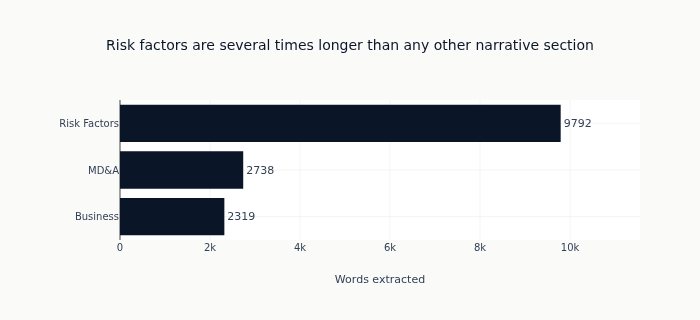

In [10]:
latest_sections = dataset.filter(pl.col("accession_no") == documents[0]["accession_no"]).sort(
    "word_count", descending=True
)
labels = {"business": "Business", "risk_factors": "Risk Factors", "mda": "MD&A"}
fig = px.bar(
    latest_sections.with_columns(label=pl.col("section").replace(labels)).to_pandas(),
    x="word_count",
    y="label",
    orientation="h",
    title="Risk factors are several times longer than any other narrative section",
    labels={"word_count": "Words extracted", "label": ""},
    color_discrete_sequence=[COLORS["blue"]],
    text="word_count",
)
fig.update_traces(textposition="outside", cliponaxis=False)
fig.update_layout(
    height=320,
    yaxis=dict(autorange="reversed"),
    xaxis_range=[0, float(latest_sections["word_count"].max()) * 1.18],
    margin=dict(l=120, r=60),
)
show_plotly_with_alt(
    fig,
    "Horizontal bar chart of the words extracted from each narrative section of the most recent "
    "filing. The risk factors bar is several times longer than the other two, which are of "
    "similar length to each other.",
)

比例是为什么风险因素是语料库中最常挖掘的章节。这也是为什么这个章节难以使用的原因：一个如此长的区块每年都会因为与业务无关的原因而略有变化，因此信号在于变化的内容，而不是它所说的内容。

## 6. 两份文件之间的变化

连续两份文件中的相同章节可以直接进行比较。有两个度量标准值得拥有，它们回答了不同的问题。**词汇集的Jaccard相似度**表示共享的语言量，这是一个漂移的度量。**在新文件中出现而在旧文件中缺失的段落**是新增内容，而这些是那些决定开始披露风险管理的名称。

In [11]:
def vocabulary_overlap(old: str, new: str) -> dict:
    """Shared vocabulary between two documents, and what each has that the other does not."""
    old_words, new_words = set(old.lower().split()), set(new.lower().split())
    union = old_words | new_words
    return {
        "jaccard_similarity": len(old_words & new_words) / len(union) if union else 0.0,
        "words_only_in_new": len(new_words - old_words),
        "words_only_in_old": len(old_words - new_words),
    }


def added_paragraphs(old: str, new: str, min_characters: int = 200) -> list[str]:
    """Paragraphs of the new document that do not appear verbatim in the old one."""
    old_paragraphs = {p.strip().lower() for p in old.split("\n\n")}
    return [
        paragraph.strip()
        for paragraph in new.split("\n\n")
        if len(paragraph.strip()) >= min_characters
        and paragraph.strip().lower() not in old_paragraphs
    ]

In [12]:
CHANGE_SECTION = "risk_factors"
newer, older = documents[0]["accession_no"], documents[1]["accession_no"]
comparable = dataset.filter(
    (pl.col("section") == CHANGE_SECTION)
    & (pl.col("quality") == "ok")
    & ~pl.col("boundary_leak")
    & pl.col("accession_no").is_in([older, newer])
)

# An extraction the quality check rejected must not enter the comparison. An empty older section
# scores zero similarity and marks every paragraph of the newer one as an addition, which reads
# as a company rewriting its risk factors rather than as a failed extraction.
if comparable.height < 2:
    additions = []
    print(f"Both filings' {CHANGE_SECTION} did not pass the quality check; no comparison made.")
else:
    texts = {row["accession_no"]: row["text"] for row in comparable.iter_rows(named=True)}
    overlap = vocabulary_overlap(texts[older], texts[newer])
    additions = added_paragraphs(texts[older], texts[newer])
    print(f"Comparing {CHANGE_SECTION} between {older} and {newer}")
    for name, value in overlap.items():
        print(f"  {name}: {value:.3f}" if isinstance(value, float) else f"  {name}: {value}")
    print(f"  paragraphs in the newer filing that are not verbatim in the older: {len(additions)}")

Comparing risk_factors between 0000320193-24-000123 and 0000320193-25-000079
  jaccard_similarity: 0.807
  words_only_in_new: 222
  words_only_in_old: 198
  paragraphs in the newer filing that are not verbatim in the older: 55


高词汇重叠和大量更改的段落是正常的结果，这也是为什么仅凭词汇度量标准本身是一个糟糕的变化检测器：一个文件可以完全重写一个段落，而不引入一个新词。

段落比较是精确的而不是模糊的，所以一个重新措辞的子句就使一个段落计为新的。这会高估变化检测信号，而不会低估任何内容，这对于一个人阅读的屏幕来说是一个更安全的方向；生产版本在段落之间评分相似度，而不是测试它们是否相等。

In [13]:
for i, paragraph in enumerate(additions[:3], 1):
    print(f"--- changed paragraph {i} ---")
    print(paragraph[:400] + ("..." if len(paragraph) > 400 else ""))
    print()

--- changed paragraph 1 ---
The following summarizes factors that could have a material adverse effect on the Company’s business, reputation, results of operations, financial condition and stock price. The Company may not be able to accurately predict, control or mitigate these risks. Statements in this section are based on the Company’s beliefs and opinions regarding matters that could materially adversely affect the Compan...

--- changed paragraph 2 ---
The Company’s operations and performance depend significantly on global and regional economic conditions and adverse economic conditions can materially adversely affect the Company’s business, results of operations, financial condition and stock price.

--- changed paragraph 3 ---
Uncertainty about, or a decline in, global or regional economic conditions can also have a significant impact on the Company’s suppliers, contract manufacturers, logistics providers, distributors, cellular network carriers and other channel partners, and de

## 7. 保存数据集

以存取号作为键的Parquet，旁边是时间戳和章节名称。原始文件文本故意不与其一起存储：它可以从存取号中重新生成，并且它的大小是原始的二十倍。

In [14]:
output_file = OUTPUT_DIR / "sec_filing_sections.parquet"
dataset.write_parquet(output_file)
print(f"Wrote {len(dataset)} rows to {output_file}")
pl.read_parquet(output_file).select("accession_no", "section", "word_count", "quality")

Wrote 6 rows to 04_fundamental_alternative_data/output/sec_text/sec_filing_sections.parquet


accession_no,section,word_count,quality
str,str,i64,str
"""0000320193-25-000079""","""business""",2319,"""ok"""
"""0000320193-25-000079""","""risk_factors""",9792,"""ok"""
"""0000320193-25-000079""","""mda""",2738,"""ok"""
"""0000320193-24-000123""","""business""",2266,"""ok"""
"""0000320193-24-000123""","""risk_factors""",9921,"""ok"""
"""0000320193-24-000123""","""mda""",2364,"""ok"""


## 关键要点

1. 项目编号是形式特定的。管理层讨论是10-K的第7项，10-Q的第一部分的第2项，因此为一种形式构建的提取器在另一种形式上会默默地返回空值。从形式类型中选择模式集，而不是默认使用它。
2. 项目标题在文件中多次出现——在目录中、在交叉引用中，以及作为章节出现一次。第一个匹配项几乎永远不会是正确的，将它们区分开来的是到下一个项目的跨度：目录条目运行一行，章节运行数千行。
3. 在清理过程中保留段落边界。它们是变化检测器比较的单位，一个将块与空格连接的转换器会不可恢复地破坏它们。
4. 报告提取率，而不是一个例子。失败是沉默的——一个在章节应该出现的地方的合理短字符串——并且在语料库规模上唯一能够捕捉到的是计数空值、短值和携带下一个项目标题的值。
5. 以存取号作为数据集的键，并携带接受时间戳。当存在修订时，公司和日期不能确定文件，并且接受时间在收盘后直到下一个会话之前不可交易。
6. 词汇重叠和更改的段落度量不同的事情。一个文件可以重写一个段落而不添加一个词，因此仅基于词汇构建的信号会错过那些重要的重写。